<a href="https://colab.research.google.com/github/kananshr13/CSET-343-Ai-in-Healthcare/blob/main/Lab_Experiment_6_CSET_343.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
# Cell 1: Install and import libraries, download dataset
!pip install -q opencv-python scikit-image scikit-learn matplotlib seaborn torch torchvision kagglehub

import os
import glob
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

print("Downloading Chest X-Ray Images (Pneumonia) dataset...")
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Dataset downloaded to:", path)

base_dir = os.path.join(path, 'chest_xray')
train_dir = os.path.join(base_dir, 'train')

normal_imgs = glob.glob(os.path.join(train_dir, 'NORMAL', '*.jpeg'))
pneumonia_imgs = glob.glob(os.path.join(train_dir, 'PNEUMONIA', '*.jpeg'))

print("=== Class Balance ===")
print(f"Normal Images: {len(normal_imgs)}")
print(f"Pneumonia Images: {len(pneumonia_imgs)}")

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset downloaded to: /kaggle/input/chest-xray-pneumonia
=== Class Balance ===
Normal Images: 1341
Pneumonia Images: 3875


--- Normal Samples ---


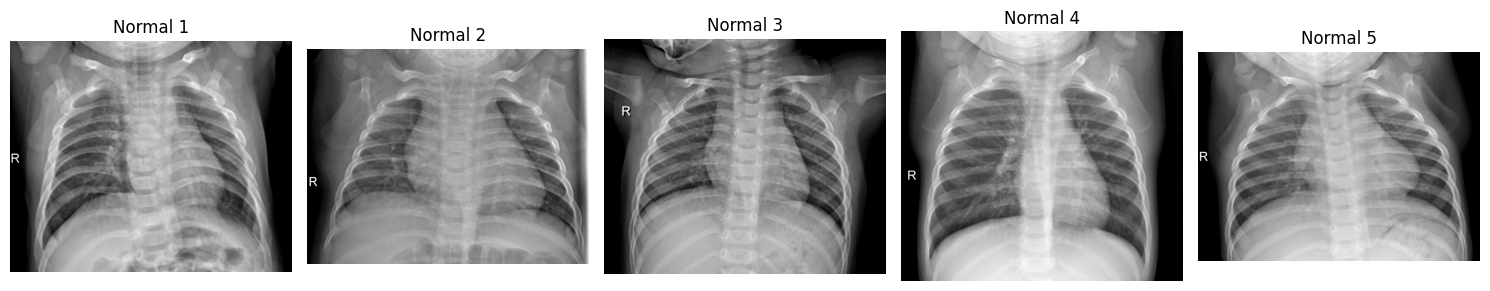

--- Pneumonia Samples ---


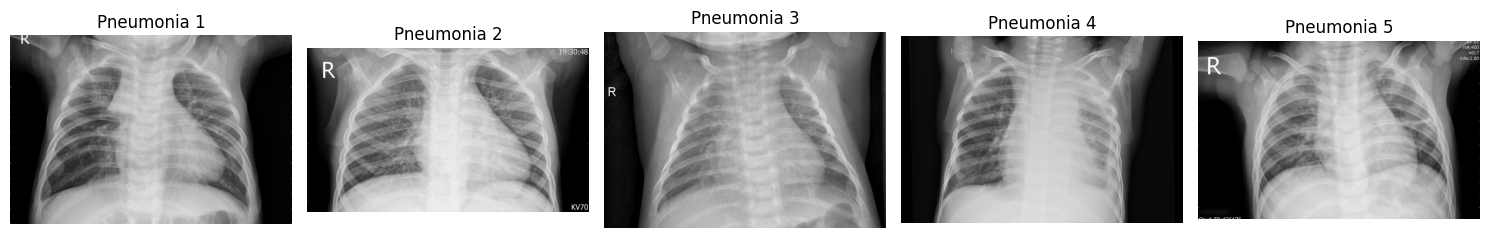

In [9]:
# Cell 2: Visualize dataset samples
def plot_samples(img_paths, class_name, num_samples=5):
    plt.figure(figsize=(15, 3))
    samples = random.sample(img_paths, num_samples)
    for i, img_path in enumerate(samples):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.subplot(1, num_samples, i + 1)
        plt.imshow(img)
        plt.title(f"{class_name} {i+1}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

print("--- Normal Samples ---")
plot_samples(normal_imgs, "Normal", 5)

print("--- Pneumonia Samples ---")
plot_samples(pneumonia_imgs, "Pneumonia", 5)

In [10]:
# Cell 3: Feature extraction and data splitting
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops
from sklearn.model_selection import train_test_split

IMG_SIZE = (128, 128)

def extract_features(img_path):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    img_resized = cv2.resize(img, IMG_SIZE)

    # 1. HOG
    hog_feat = hog(img_resized, orientations=8, pixels_per_cell=(16, 16),
                   cells_per_block=(1, 1), visualize=False)

    # 2. LBP
    lbp = local_binary_pattern(img_resized, P=8, R=1, method='uniform')
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 11), range=(0, 10))
    lbp_hist = lbp_hist.astype("float")
    lbp_hist /= (lbp_hist.sum() + 1e-6)

    # 3. GLCM
    glcm = graycomatrix(img_resized, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    dissimilarity = graycoprops(glcm, 'dissimilarity')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]
    glcm_feat = np.array([contrast, dissimilarity, homogeneity, energy, correlation])

    return np.hstack([hog_feat, lbp_hist, glcm_feat])

# Sampling a subset of 2000 images for fast execution
all_paths = normal_imgs[:1000] + pneumonia_imgs[:1000]
all_labels = [0] * len(normal_imgs[:1000]) + [1] * len(pneumonia_imgs[:1000])

X, y = [], []
print("Extracting features from images...")
for p, l in zip(all_paths, all_labels):
    X.append(extract_features(p))
    y.append(l)

X = np.array(X)
y = np.array(y)

# 70% Train, 15% Validation, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f"Feature Vector Length: {X.shape[1]}")
print(f"Train Set: {X_train.shape[0]} | Val Set: {X_val.shape[0]} | Test Set: {X_test.shape[0]}")

Extracting features from images...
Feature Vector Length: 527
Train Set: 1400 | Val Set: 300 | Test Set: 300


In [11]:
# Cell 4: Train traditional models
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

svm_model = SVC(probability=True, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

svm_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

def evaluate_model(model, X_t, y_t, model_name="Model"):
    preds = model.predict(X_t)
    probs = model.predict_proba(X_t)[:, 1]
    print(f"=== {model_name} Test Results ===")
    print(f"Accuracy:  {accuracy_score(y_t, preds):.4f}")
    print(f"Precision: {precision_score(y_t, preds):.4f}")
    print(f"Recall:    {recall_score(y_t, preds):.4f}")
    print(f"F1-Score:  {f1_score(y_t, preds):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_t, probs):.4f}\n")
    return preds, probs

svm_preds, svm_probs = evaluate_model(svm_model, X_test, y_test, "SVM")
rf_preds, rf_probs = evaluate_model(rf_model, X_test, y_test, "Random Forest")

=== SVM Test Results ===
Accuracy:  0.7467
Precision: 0.8426
Recall:    0.6067
F1-Score:  0.7054
ROC-AUC:   0.8183

=== Random Forest Test Results ===
Accuracy:  0.9367
Precision: 0.9580
Recall:    0.9133
F1-Score:  0.9352
ROC-AUC:   0.9832



Training CNN model...
=== CNN Test Results ===
Accuracy:  0.9750
Precision: 1.0000
Recall:    0.9750
F1-Score:  0.9873
ROC-AUC:   nan



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


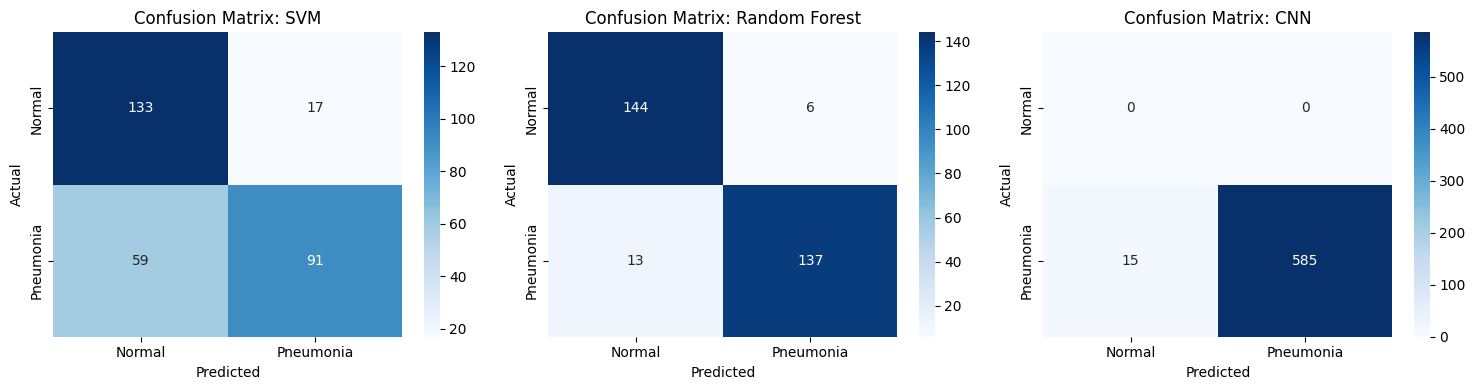

In [12]:
# Cell 5: CNN Training and Comparison
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image
from sklearn.metrics import confusion_matrix

class PneumoniaDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = PneumoniaDataset(all_paths[:1400], all_labels[:1400], transform=transform)
test_dataset = PneumoniaDataset(all_paths[1400:], all_labels[1400:], transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.fc1 = nn.Linear(32 * 32 * 32, 64)
        self.fc2 = nn.Linear(64, 2)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        return self.fc2(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn_model = CNNModel().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

print("Training CNN model...")
cnn_model.train()
for epoch in range(5):
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(cnn_model(imgs), labels)
        loss.backward()
        optimizer.step()

cnn_model.eval()
cnn_true, cnn_preds, cnn_probs = [], [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = cnn_model(imgs)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        _, preds = torch.max(outputs, 1)
        cnn_true.extend(labels.numpy())
        cnn_preds.extend(preds.cpu().numpy())
        cnn_probs.extend(probs.cpu().numpy())

print("=== CNN Test Results ===")
print(f"Accuracy:  {accuracy_score(cnn_true, cnn_preds):.4f}")
print(f"Precision: {precision_score(cnn_true, cnn_preds):.4f}")
print(f"Recall:    {recall_score(cnn_true, cnn_preds):.4f}")
print(f"F1-Score:  {f1_score(cnn_true, cnn_preds):.4f}")
print(f"ROC-AUC:   {roc_auc_score(cnn_true, cnn_probs):.4f}\n")

# Plot Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
models_data = [("SVM", y_test, svm_preds), ("Random Forest", y_test, rf_preds), ("CNN", cnn_true, cnn_preds)]

for ax, (name, y_t, y_p) in zip(axes, models_data):
    cm = confusion_matrix(y_t, y_p)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Normal', 'Pneumonia'], yticklabels=['Normal', 'Pneumonia'])
    ax.set_title(f'Confusion Matrix: {name}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()